# EDA — Gearbox Faults

Source: [Gearbox Fault Diagnosis dataset](https://www.kaggle.com/datasets/brjapon/gearbox-fault-diagnosis).

Expected data location: `data/raw/gearbox/`. The raw dataset contains four vibration channels for healthy and broken-tooth conditions at several load levels.

In [1]:
%pip install -q pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_dir = project_dir / 'data' / 'raw' / 'gearbox'
assert data_dir.exists(), 'Run download_datasets.ipynb first.'

files = sorted(file for file in data_dir.rglob('*') if file.suffix.lower() in {'.txt', '.csv'})
assert files, f'No TXT or CSV files found in {data_dir}'

def condition(file):
    name = file.stem.lower()
    if name.startswith('b') or 'broken' in name:
        return 'broken_tooth'
    if name.startswith('h') or 'healthy' in name:
        return 'healthy'
    return 'unknown'

def load_percent(file):
    match = re.search(r'hz(\d+)', file.stem.lower())
    return int(match.group(1)) if match else None

inventory = pd.DataFrame({
    'file': [str(file.relative_to(data_dir)) for file in files],
    'condition': [condition(file) for file in files],
    'load_percent': [load_percent(file) for file in files],
    'size_mb': [round(file.stat().st_size / 1_000_000, 2) for file in files],
})
display(inventory.head())
display(inventory.groupby(['condition', 'load_percent'], dropna=False).size().rename('files').reset_index())
print(f'Files found: {len(files)}')

,file,condition,load_percent,size_mb
0,BrokenTooth\b30hz0.csv,broken_tooth,0,3.08
1,BrokenTooth\b30hz10.csv,broken_tooth,10,3.89
2,BrokenTooth\b30hz20.csv,broken_tooth,20,3.97
3,BrokenTooth\b30hz30.csv,broken_tooth,30,3.11
4,BrokenTooth\b30hz40.csv,broken_tooth,40,3.26


,condition,load_percent,files
0,broken_tooth,0,1
1,broken_tooth,10,1
2,broken_tooth,20,1
3,broken_tooth,30,1
4,broken_tooth,40,1
5,broken_tooth,50,1
6,broken_tooth,60,1
7,broken_tooth,70,1
8,broken_tooth,80,1
9,broken_tooth,90,1


Files found: 20


## EDA block 1 — inspect one vibration record

The raw files are expected to use whitespace or comma delimiters with four vibration channels.

Sample file: b30hz0.csv
Condition: broken_tooth | Load: 0%
Shape of first 5,000 rows: (4999, 4)


,a1,a2,a3,a4
1,2.350390,1.454870,-1.667080,-2.055610
2,2.452970,1.400100,-2.825100,0.984487
3,-0.241284,-0.267390,0.793540,0.605862
4,1.130270,-0.890918,0.696969,0.613068
5,-1.296140,0.980479,-1.130560,-0.346971


,count,mean,std,min,max
a1,4999.0,0.012578,3.452386,-16.3548,19.0489
a2,4999.0,0.020714,3.803655,-16.5693,15.5054
a3,4999.0,0.020088,3.060870,-11.4722,15.4648
a4,4999.0,-0.077104,3.319090,-18.8941,14.3429


,missing
a1,0
a2,0
a3,0
a4,0


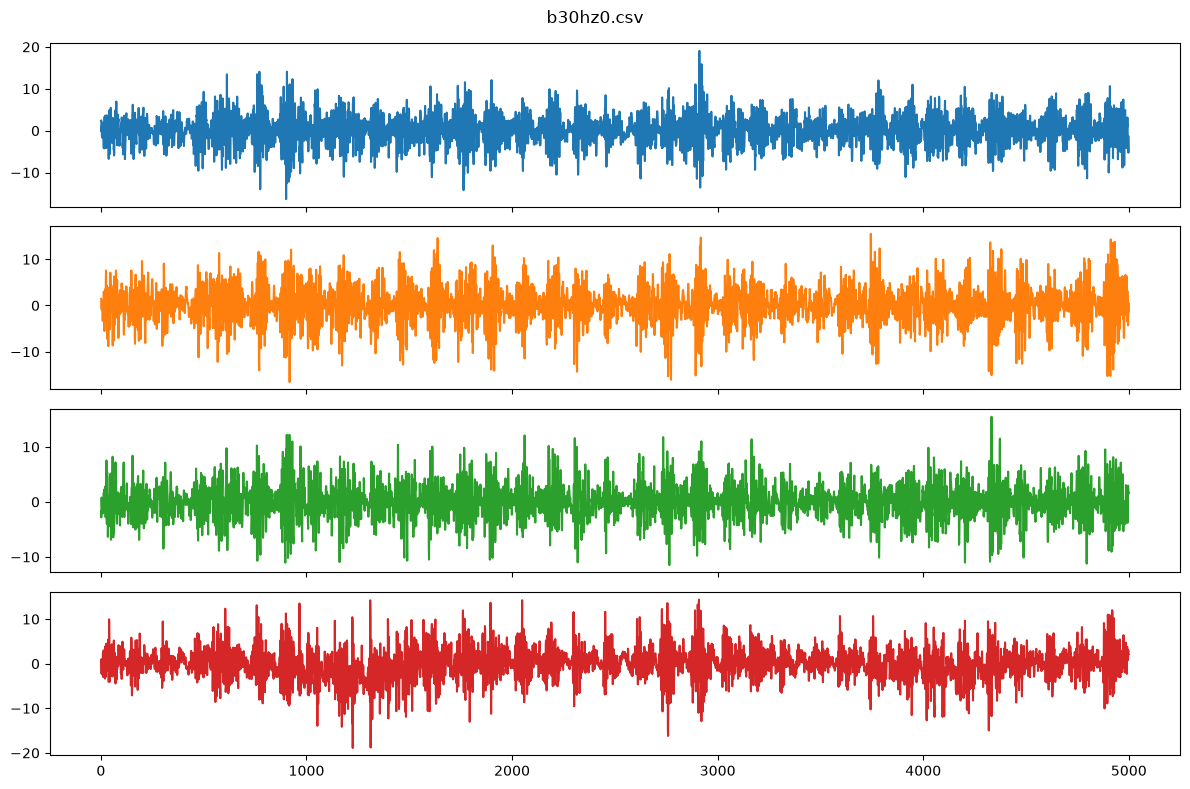

In [3]:
def read_signal(file, rows=5_000):
    return pd.read_csv(file, sep=r'[\s,;]+', engine='python', header=None, nrows=rows)

sample_file = files[0]
sample = read_signal(sample_file)
sample = sample.apply(pd.to_numeric, errors='coerce').dropna(how='all')
sample.columns = ['a1', 'a2', 'a3', 'a4'] if sample.shape[1] == 4 else [f'sensor_{i}' for i in range(sample.shape[1])]

print(f'Sample file: {sample_file.name}')
print(f'Condition: {condition(sample_file)} | Load: {load_percent(sample_file)}%')
print(f'Shape of first 5,000 rows: {sample.shape}')
display(sample.head())
display(sample.describe().T[['count', 'mean', 'std', 'min', 'max']])
display(sample.isna().sum().rename('missing').to_frame())

sample.plot(subplots=True, figsize=(12, 8), legend=False, title=sample_file.name)
plt.tight_layout()
plt.show()